# Used Car Valuation - Exploratory Data Analysis (EDA)
This notebook analyzes vehicle attributes, pricing behavior, categorical distributions, and linear relationships.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual configurations
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)

### 1. Ingest Raw Dataset

In [2]:
# Access raw CSV from the designated raw data directory
source_path = os.path.join('..', 'data', 'raw data', 'car data.csv')
car_df = pd.read_csv(source_path)

print(f'Records: {car_df.shape[0]} | Attributes: {car_df.shape[1]}')
car_df.head(5)

Records: 201 | Attributes: 9


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


### 2. Dataset Schema & Integrity Check

In [3]:
# Verify data types and null presence
car_df.info()

print('\nMissing values count:')
print(car_df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 201 entries, 0 to 200
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       201 non-null    object 
 1   Year           201 non-null    int64  
 2   Selling_Price  201 non-null    float64
 3   Present_Price  201 non-null    float64
 4   Kms_Driven     201 non-null    int64  
 5   Fuel_Type      201 non-null    object 
 6   Seller_Type    201 non-null    object 
 7   Transmission   201 non-null    object 
 8   Owner          201 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 14.3+ KB

Missing values count:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64


### 3. Summary Statistics

In [4]:
# Statistical distribution across numerical columns
car_df.describe().round(2)

,Year,Selling_Price,Present_Price,Kms_Driven,Owner
count,201.00,201.00,201.00,201.00,201.00
mean,2013.59,6.66,10.93,41238.69,0.03
std,2.88,5.16,8.89,27448.51,0.25
min,2003.00,0.35,0.88,2071.00,0.00
25%,2012.00,3.60,6.40,21780.00,0.00
50%,2014.00,5.25,8.50,40000.00,0.00
75%,2016.00,7.50,13.46,53460.00,0.00
max,2018.00,35.00,92.60,197176.00,3.00


### 4. Target Variable Analysis (Selling Price)

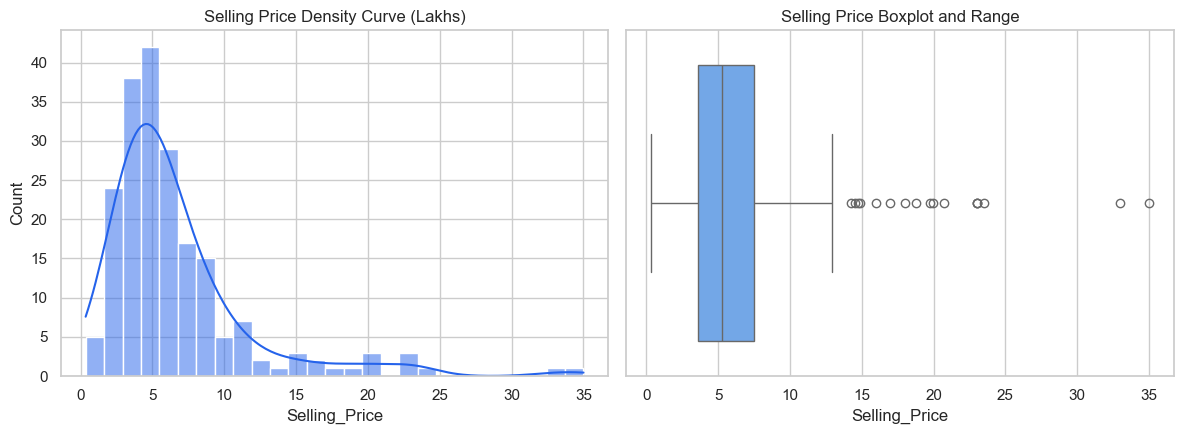

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(car_df['Selling_Price'], kde=True, color='#2563eb', ax=ax1)
ax1.set_title('Selling Price Density Curve (Lakhs)')

sns.boxplot(x=car_df['Selling_Price'], color='#60a5fa', ax=ax2)
ax2.set_title('Selling Price Boxplot and Range')
plt.tight_layout()
plt.show()

### 5. Categorical Attribute Breakdown

C:\Users\Rajguru\AppData\Local\Temp\ipykernel_9396\2016665133.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=car_df, x=category, palette='Blues_r', ax=ax)
C:\Users\Rajguru\AppData\Local\Temp\ipykernel_9396\2016665133.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=car_df, x=category, palette='Blues_r', ax=ax)
C:\Users\Rajguru\AppData\Local\Temp\ipykernel_9396\2016665133.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=car_df, x=category, palette='Blues_r', ax=ax)
C:\Users\Rajguru\AppData\Local\Temp\ipykernel_

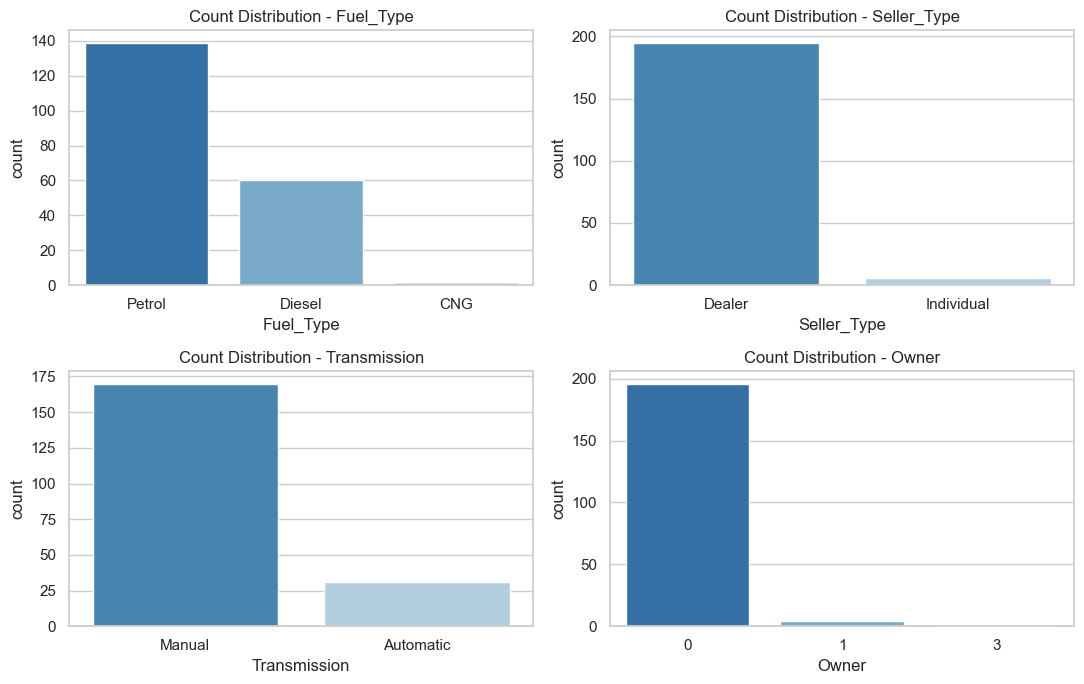

In [6]:
categories = ['Fuel_Type', 'Seller_Type', 'Transmission', 'Owner']
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, category in zip(axes.flatten(), categories):
    sns.countplot(data=car_df, x=category, palette='Blues_r', ax=ax)
    ax.set_title(f'Count Distribution - {category}')
plt.tight_layout()
plt.show()

### 6. Feature Correlation Matrix

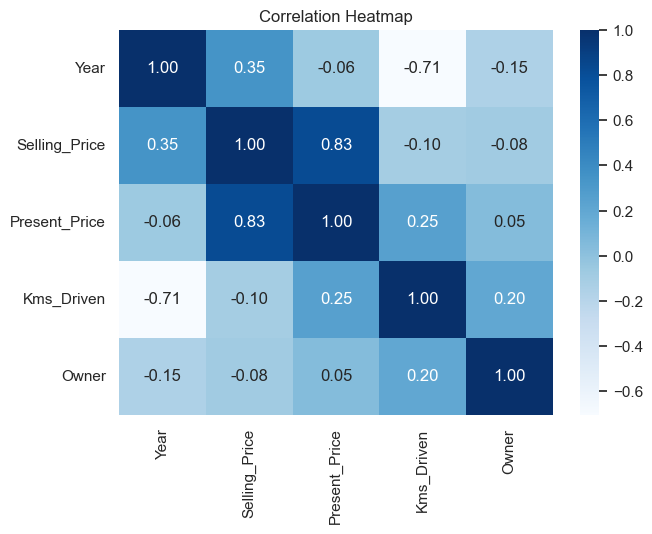

In [7]:
numeric_sub = car_df.select_dtypes(include=np.number)
plt.figure(figsize=(7, 5))
sns.heatmap(numeric_sub.corr(), annot=True, cmap='Blues', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()